In [170]:
from MyPlotRecipe.SharedX import ShareXaxis
from MyPlotRecipe.UniversalColor import UniversalColor
from MyPlotRecipe.legend_shadow import legend_shadow
import numpy as np
import math
import datetime

from scipy import signal
from scipy.optimize import curve_fit
from scipy import stats
from scipy.stats import t as t_dist
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
from scipy.spatial import KDTree
from scipy.interpolate import RegularGridInterpolator
import matplotlib.pyplot as plt
import matplotlib.ticker as ptick
import matplotlib.colors as mplC
import colorsys
from matplotlib.ticker import FixedLocator
from matplotlib.ticker import AutoMinorLocator
import matplotlib.dates as mdates
from matplotlib.patches import FancyArrowPatch, Rectangle
from matplotlib.patches import Wedge
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

import cmocean

from CSField import CSField
import JupiterMag as jm

jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

UC = UniversalColor()
UC.set_palette()

F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

In [171]:
# ============================================================
# 重みづけ最小二乗フィット（1次関数） y = a*x + b
# ============================================================

def weighted_linear_fit(x, y, w):
    """
    重みづけ最小二乗フィット (1次関数)

    Parameters
    ----------
    x     : array-like  説明変数
    y     : array-like  目的変数
    sigma : array-like  各点の標準偏差（測定誤差）

    Returns
    -------
    a, b        : フィット係数 (y = a*x + b)
    sigma_a, sigma_b : 各係数の標準誤差
    """
    # 重みづけ和
    Sw = np.sum(w)
    Swx = np.sum(w * x)
    Swx2 = np.sum(w * x**2)
    Swy = np.sum(w * y)
    Swxy = np.sum(w * x * y)

    # 行列式
    delta = Sw * Swx2 - Swx**2

    # 解析解
    a = (Sw * Swxy - Swx * Swy) / delta
    b = (Swx2 * Swy - Swx * Swxy) / delta

    # 標準誤差
    sigma_a = np.sqrt(Sw / delta)
    sigma_b = np.sqrt(Swx2 / delta)

    return a, b, sigma_a, sigma_b

In [172]:
def day2hhmm(decimal_day):
    doy = int(decimal_day)
    rest = decimal_day - doy

    hours = int(rest*24)
    minutes = (rest*24-hours)*60

    if round(minutes) >= 60:
        hours += 1
        minutes = 0
    else:
        minutes = round(minutes)
    return hours, minutes


def hhmm2day(hours, minutes, seconds=0):
    fraction_of_day = hours/24 + minutes/(60*24) + seconds/(60*60*24)
    return fraction_of_day


def fmt_hhmm(decimal_day):
    hours, minutes = day2hhmm(decimal_day)
    hh = '{:02}'.format(hours)
    mm = '{:02}'.format(minutes)
    return hh+':'+mm

In [173]:
# Data from Connerney+2020: PJ index
con20_pj_idx = np.array([1, 3, 4, 5, 6,
                        7, 8, 9, 10, 11,
                        12, 13, 14, 15, 16,
                        17, 18, 19, 20, 21,
                        22, 23, 24], dtype=int)

# Data from Connerney+2020: Current constant [nT]
con20_mu_i_tot = np.array([150.1, 137.8, 127.2, 129.1, 130.1,
                           142.3, 140.1, 143.8, 137.0, 141.4,
                           124.2, 148.9, 145.3, 144.8, 149.9,
                           132.1, 133.5, 152.9, 138.5, 138.8,
                           156.1, 141.4, 146.3])

# Data from Connerney+2020: Radial current constant [MA]
con20_mu_i_rho = np.array([35.2, 14.6, 7.7, 11.5, 20.8,
                           20.2, 12.2, 21.1, 20.9, 10.7,
                           26.26, 16.4, 12.0, 19.6, 12.0,
                           13.6, 20.0, 12.8, 16.0, 17.3,
                           9.9, 16.1, 10.3])

In [174]:
# 定数
MU0 = 4*np.pi*1E-7       # 真空中の透磁率 [H m-1]
AMU2KG = 1.66E-27        # [kg]
RJ = 71492*1E+3  # Jupiter radius [m]
RE = 1560*1E+3   # Europa radius [m]
# Angular velocity of Jupiter System III rotation [rad sec-1]
OMG_J = 2*np.pi/(9.55*3600)
OMG_G = 2*np.pi/(7.2*24*3600)   # Ganymede orbital angular velosity [rad/sec]

Psyn_eu = (11.22)*3600      # Moon's synodic period [sec]
Psyn_ga = (10.53)*3600      # Moon's synodic period [sec]

In [175]:
PJ_list = [1, 3, 4, 5,
           6, 7, 8, 9, 10,
           11, 12, 13, 14, 15,
           16, 17, 18, 19, 20,
           21, 22, 23, 24, 25,
           26, 27, 28, 29, 30,
           31, 32, 33, 34, 35,
           36, 37, 38, 39, 40,
           41, 42, 43, 44, 45,
           46, 47, 48, 49, 50,
           51, 52, 53, 54, 55,
           56, 57, 58, 59, 60,
           61, 62, 63, 64, 65,
           66, 67, 68, 69, 70,
           71, 72, 73, 74, 75,
           76, 77, 78, 79, 80]
dir = 'results/insitu_fit_a0_a1_b4_v2_36rj'
f0 = np.loadtxt(dir+'/result_PJ' +
                str(PJ_list[0]).zfill(2)+'_PJ'+str(PJ_list[-1]).zfill(2)+'.txt')

In [176]:
plot_in = 3.0       # Inner edge [RJ]
plot_out = 40.0     # Outer edge [RJ]

# 全データ

# Field line trace

In [177]:
jm.Internal.Config(Model='jrm33', Degree=1, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')
csfield = CSField()
csfield.config(
    i_phi0=4.838275473116932E-5,  # 4.845093370096503E-5
    I_rho0=10.033388761574646,    # 10.45591036962724
    a0=2.8333677E-6,              # 1.87067601E-6
    MLT0=1.56400572,              # 2.7409048
    a1=14.95621835,               # 25.56805279
    MLT1=19.83627108,             # 18.83227378
    b1=4.2518,
    MLTb=-0.2086,
    D=5.0*math.sqrt(5/3),
)

In [178]:
# ==============================================================
# FIELD LINE TRACE IN THE CURRENT SHEET PLANE (1800 MLT DUSK)
# FROM NORTHERN IONOSPHERE
# ==============================================================
r_cs = (66854.0+500.0)*1E+3  # [m]
theta_cs = np.radians(
    np.array([2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 15.0, 16.0,
              17.0, 18.0, 20.0, 22.0, 24.0, 26.0, 28.0, 30.0])
)  # Colatitude [rad]
phi_cs = 0.0  # [rad]

R = csfield.R_sys3_2_cs()
RT = csfield.R_cs_2_sys3()

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

Niter = 50000

ds0 = 500000.0   # [m]
p = 1.2

result_arr_N = np.zeros((x_cs0.size, 3, int(Niter/10)))

# 北半球から南半球へ
ns = 1     # -1: north; 1: south
for j in range(x_cs0.size):
    k = 0
    pos_s3_0 = RT @ np.array([
        x_cs0[j], y_cs0[j], z_cs0[j]
    ])                      # [m]
    x = pos_s3_0[0].copy()  # [m]
    y = pos_s3_0[1].copy()  # [m]
    z = pos_s3_0[2].copy()  # [m]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=18.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]

        # Sys III -> CS
        B_vec_cs = R @ np.array([float(Bx), float(By), float(Bz)])
        x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
        rho_cs = np.sqrt(x_cs**2 + y_cs**2)
        phi_cs = np.arctan2(y_cs, x_cs)
        B_rho_cs = B_vec_cs[0]*np.cos(phi_cs) + B_vec_cs[1]*np.sin(phi_cs)
        B_phi_cs = 0.0     # rho_cs - z_cs plane
        B_z_cs = B_vec_cs[2]
        B_vec_cs = np.array([
            B_rho_cs * np.cos(phi_cs) - B_phi_cs * np.sin(phi_cs),
            B_rho_cs * np.sin(phi_cs) + B_phi_cs * np.cos(phi_cs),
            B_z_cs
        ])

        # CS -> Sys III
        B_vec_s3 = RT @ B_vec_cs
        B0 = math.sqrt(
            B_vec_s3[0]**2+B_vec_s3[1]**2+B_vec_s3[2]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*B_vec_s3[0]/B0)*ns
        y += (ds*B_vec_s3[1]/B0)*ns
        z += (ds*B_vec_s3[2]/B0)*ns

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            result_arr_N[j, 0, k] = x_cs
            result_arr_N[j, 1, k] = y_cs
            result_arr_N[j, 2, k] = z_cs
            k += 1

        # 終了条件 (北の外側境界)
        if z > 55.0*RJ:
            print('North edge [RJ]:')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if rs < (66854.0+500.0-1.0)*1E+3:
            print('Jupiter surface')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

North edge [RJ]:
57.21538536706598 6.457032651874602
North edge [RJ]:
61.60612988713337 11.373863523392812
North edge [RJ]:
70.61757294603248 18.156083573662535
Horizontal edge
76.95213601113696 24.59672962409758
Horizontal edge
67.71726630426893 24.59542112510473
Horizontal edge
62.25243317412558 24.59853332026744
Horizontal edge
60.020834121293234 24.59603551540774
Horizontal edge
60.556039427090965 24.599442214367198
Jupiter surface
0.9414070262183224 0.03376027714811287
Jupiter surface
0.9417689590120908 0.04038422968674119
Jupiter surface
0.9415888994322981 0.046982830403846036
Jupiter surface
0.9413042977501349 0.06019112030326596
Jupiter surface
0.941343460194253 0.07340102073710503
Jupiter surface
0.941550980210677 0.08657063781829383
Jupiter surface
0.941495471789051 0.09960085392983309
Jupiter surface
0.9417219946965705 0.11257477616541837
Jupiter surface
0.9414052449236978 0.12529350153140242


In [179]:
# ==============================================================
# FIELD LINE TRACE IN THE CURRENT SHEET PLANE (1800 MLT DUSK)
# FROM SOUTHERN IONOSPHERE
# ==============================================================
r_cs = (66854.0+500.0)*1E+3  # [m]
theta_cs = np.radians(
    np.array([-178.0, -176.0, -174.0, -172.0, -170.0, -168.0, -166.0, -165.0])
)  # Colatitude [rad]
phi_cs = 0.0  # [rad]

R = csfield.R_sys3_2_cs()
RT = csfield.R_cs_2_sys3()

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

Niter = 50000

ds0 = 500000.0   # [m]
p = 1.2

result_arr_S = np.zeros((x_cs0.size, 3, int(Niter/10)))

# 南半球から北半球へ
ns = -1     # -1: north; 1: south
for j in range(x_cs0.size):
    k = 0
    pos_s3_0 = RT @ np.array([
        x_cs0[j], y_cs0[j], z_cs0[j]
    ])                      # [m]
    x = pos_s3_0[0].copy()  # [m]
    y = pos_s3_0[1].copy()  # [m]
    z = pos_s3_0[2].copy()  # [m]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=18.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]

        # Sys III -> CS
        B_vec_cs = R @ np.array([float(Bx), float(By), float(Bz)])
        x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
        rho_cs = np.sqrt(x_cs**2 + y_cs**2)
        phi_cs = np.arctan2(y_cs, x_cs)
        B_rho_cs = B_vec_cs[0]*np.cos(phi_cs) + B_vec_cs[1]*np.sin(phi_cs)
        B_phi_cs = 0.0     # rho_cs - z_cs plane
        B_z_cs = B_vec_cs[2]
        B_vec_cs = np.array([
            B_rho_cs * np.cos(phi_cs) - B_phi_cs * np.sin(phi_cs),
            B_rho_cs * np.sin(phi_cs) + B_phi_cs * np.cos(phi_cs),
            B_z_cs
        ])

        # CS -> Sys III
        B_vec_s3 = RT @ B_vec_cs
        B0 = math.sqrt(
            B_vec_s3[0]**2+B_vec_s3[1]**2+B_vec_s3[2]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*B_vec_s3[0]/B0)*ns
        y += (ds*B_vec_s3[1]/B0)*ns
        z += (ds*B_vec_s3[2]/B0)*ns

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            result_arr_S[j, 0, k] = x_cs
            result_arr_S[j, 1, k] = y_cs
            result_arr_S[j, 2, k] = z_cs
            k += 1

        # 終了条件 (北の外側境界)
        if z < -55.0*RJ:
            print('South edge [RJ]:')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if rs < (66854.0+500.0-1.0)*1E+3:
            print('Jupiter surface')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

South edge [RJ]:
57.21538536706579 -6.457032651874326
South edge [RJ]:
61.60612988713351 -11.373863523392641
South edge [RJ]:
70.61757294603223 -18.15608357366263
Horizontal edge
76.9521360111371 -24.596729624097687
Horizontal edge
67.71726630426936 -24.595421125104888
Horizontal edge
62.252433174125535 -24.598533320267478
Horizontal edge
60.02083412129331 -24.596035515407696
Horizontal edge
60.55603942709183 -24.599442214367457


In [180]:
# ==============================================================
# FIELD LINE TRACE IN THE CURRENT SHEET PLANE (0600 MLT DAWN)
# FROM NORTHERN IONOSPHERE
# ==============================================================
r_cs = (66854.0+500.0)*1E+3  # [m]
theta_cs = np.radians(
    np.array([2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 15.0, 16.0,
              17.0, 18.0, 20.0, 22.0, 24.0, 26.0, 28.0, 30.0])
)  # Colatitude [rad]
phi_cs = 0.0  # [rad]

R = csfield.R_sys3_2_cs()
RT = csfield.R_cs_2_sys3()

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

Niter = 50000

ds0 = 500000.0   # [m]
p = 1.2

result_arr_N2 = np.zeros((x_cs0.size, 3, int(Niter/10)))

# 北半球から南半球へ
ns = 1     # -1: north; 1: south
for j in range(x_cs0.size):
    k = 0
    pos_s3_0 = RT @ np.array([
        x_cs0[j], y_cs0[j], z_cs0[j]
    ])                      # [m]
    x = pos_s3_0[0].copy()  # [m]
    y = pos_s3_0[1].copy()  # [m]
    z = pos_s3_0[2].copy()  # [m]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=6.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]

        # Sys III -> CS
        B_vec_cs = R @ np.array([float(Bx), float(By), float(Bz)])
        x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
        rho_cs = np.sqrt(x_cs**2 + y_cs**2)
        phi_cs = np.arctan2(y_cs, x_cs)
        B_rho_cs = B_vec_cs[0]*np.cos(phi_cs) + B_vec_cs[1]*np.sin(phi_cs)
        B_phi_cs = 0.0     # rho_cs - z_cs plane
        B_z_cs = B_vec_cs[2]
        B_vec_cs = np.array([
            B_rho_cs * np.cos(phi_cs) - B_phi_cs * np.sin(phi_cs),
            B_rho_cs * np.sin(phi_cs) + B_phi_cs * np.cos(phi_cs),
            B_z_cs
        ])

        # CS -> Sys III
        B_vec_s3 = RT @ B_vec_cs
        B0 = math.sqrt(
            B_vec_s3[0]**2+B_vec_s3[1]**2+B_vec_s3[2]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*B_vec_s3[0]/B0)*ns
        y += (ds*B_vec_s3[1]/B0)*ns
        z += (ds*B_vec_s3[2]/B0)*ns

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
            result_arr_N2[j, 0, k] = x_cs
            result_arr_N2[j, 1, k] = y_cs
            result_arr_N2[j, 2, k] = z_cs
            k += 1

        # 終了条件 (北の外側境界)
        if z > 55.0*RJ:
            print('North edge [RJ]:')
            result_arr_N2[j, 0, k:] = np.nan
            result_arr_N2[j, 1, k:] = np.nan
            result_arr_N2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_N2[j, 0, k:] = np.nan
            result_arr_N2[j, 1, k:] = np.nan
            result_arr_N2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < (66854.0+500.0-1.0)*1E+3:
            print('Jupiter surface')
            result_arr_N2[j, 0, k:] = np.nan
            result_arr_N2[j, 1, k:] = np.nan
            result_arr_N2[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

North edge [RJ]:
57.18908672213973 6.4217057286629595
North edge [RJ]:
61.44467040961035 11.227843315860419
North edge [RJ]:
69.1194321125465 17.157328749006947
Horizontal edge
79.30030746668413 24.596609908847224
Horizontal edge
68.81631339230223 24.596630086756072
Horizontal edge
62.76256347127163 24.597889473261237
Horizontal edge
60.09906675469841 24.597297947254322
Horizontal edge
60.215840363100405 24.598333198862807
Jupiter surface
0.9416161851031483 0.03380699087272688
Jupiter surface
0.9413091391505847 0.04035588539764751
Jupiter surface
0.9418630512809844 0.0470255673011241
Jupiter surface
0.9415840281833916 0.06023475408210817
Jupiter surface
0.9420254499042766 0.07351088845490837
Jupiter surface
0.9416470107196964 0.08658999235674039
Jupiter surface
0.9415515230384052 0.09961357211367225
Jupiter surface
0.941714219332656 0.11257418747087175
Jupiter surface
0.9420743868548851 0.1254556587311316


In [181]:
# ==============================================================
# FIELD LINE TRACE IN THE CURRENT SHEET PLANE (0600 MLT DAWN)
# FROM SOUTHERN IONOSPHERE
# ==============================================================
r_cs = (66854.0+500.0)*1E+3  # [m]
theta_cs = np.radians(
    np.array([-178.0, -176.0, -174.0, -172.0, -170.0, -168.0, -166.0, -165.0])
)  # Colatitude [rad]
phi_cs = 0.0  # [rad]

R = csfield.R_sys3_2_cs()
RT = csfield.R_cs_2_sys3()

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

Niter = 50000

ds0 = 500000.0   # [m]
p = 1.2

result_arr_S2 = np.zeros((x_cs0.size, 3, int(Niter/10)))

# 南半球から北半球へ
ns = -1     # -1: north; 1: south
for j in range(x_cs0.size):
    k = 0
    pos_s3_0 = RT @ np.array([
        x_cs0[j], y_cs0[j], z_cs0[j]
    ])                      # [m]
    x = pos_s3_0[0].copy()  # [m]
    y = pos_s3_0[1].copy()  # [m]
    z = pos_s3_0[2].copy()  # [m]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=6.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]

        # Sys III -> CS
        B_vec_cs = R @ np.array([float(Bx), float(By), float(Bz)])
        x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
        rho_cs = np.sqrt(x_cs**2 + y_cs**2)
        phi_cs = np.arctan2(y_cs, x_cs)
        B_rho_cs = B_vec_cs[0]*np.cos(phi_cs) + B_vec_cs[1]*np.sin(phi_cs)
        B_phi_cs = 0.0     # rho_cs - z_cs plane
        B_z_cs = B_vec_cs[2]
        B_vec_cs = np.array([
            B_rho_cs * np.cos(phi_cs) - B_phi_cs * np.sin(phi_cs),
            B_rho_cs * np.sin(phi_cs) + B_phi_cs * np.cos(phi_cs),
            B_z_cs
        ])

        # CS -> Sys III
        B_vec_s3 = RT @ B_vec_cs
        B0 = math.sqrt(
            B_vec_s3[0]**2+B_vec_s3[1]**2+B_vec_s3[2]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*B_vec_s3[0]/B0)*ns
        y += (ds*B_vec_s3[1]/B0)*ns
        z += (ds*B_vec_s3[2]/B0)*ns

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
            result_arr_S2[j, 0, k] = x_cs
            result_arr_S2[j, 1, k] = y_cs
            result_arr_S2[j, 2, k] = z_cs
            k += 1

        # 終了条件 (北の外側境界)
        if z < -55.0*RJ:
            print('South edge [RJ]:')
            result_arr_S2[j, 0, k:] = np.nan
            result_arr_S2[j, 1, k:] = np.nan
            result_arr_S2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_S2[j, 0, k:] = np.nan
            result_arr_S2[j, 1, k:] = np.nan
            result_arr_S2[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < (66854.0+500.0-1.0)*1E+3:
            print('Jupiter surface')
            result_arr_S2[j, 0, k:] = np.nan
            result_arr_S2[j, 1, k:] = np.nan
            result_arr_S2[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

South edge [RJ]:
57.1890867221398 -6.421705728663017
South edge [RJ]:
61.44467040961061 -11.227843315860397
South edge [RJ]:
69.11943211254652 -17.157328749007
Horizontal edge
79.30030746668395 -24.59660990884735
Horizontal edge
68.81631339230239 -24.596630086756
Horizontal edge
62.76256347127139 -24.597889473261183
Horizontal edge
60.09906675469837 -24.5972979472543
Horizontal edge
60.21584036310071 -24.598333198862754


In [182]:
# ==============================================================
# FIELD LINE TRACE IN THE CURRENT SHEET PLANE (0300 MLT DAWN)
# FROM NORTHERN IONOSPHERE
# ==============================================================
r_cs = (66854.0+500.0)*1E+3  # [m]
theta_cs = np.radians(
    np.array([2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 15.0, 16.0,
              17.0, 18.0, 20.0, 22.0, 24.0, 26.0, 28.0, 30.0])
)  # Colatitude [rad]
phi_cs = 0.0  # [rad]

R = csfield.R_sys3_2_cs()
RT = csfield.R_cs_2_sys3()

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

Niter = 50000

ds0 = 500000.0   # [m]
p = 1.2

result_arr_N3 = np.zeros((x_cs0.size, 3, int(Niter/10)))

# 北半球から南半球へ
ns = 1     # -1: north; 1: south
for j in range(x_cs0.size):
    k = 0
    pos_s3_0 = RT @ np.array([
        x_cs0[j], y_cs0[j], z_cs0[j]
    ])                      # [m]
    x = pos_s3_0[0].copy()  # [m]
    y = pos_s3_0[1].copy()  # [m]
    z = pos_s3_0[2].copy()  # [m]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=6.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]

        # Sys III -> CS
        B_vec_cs = R @ np.array([float(Bx), float(By), float(Bz)])
        x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
        rho_cs = np.sqrt(x_cs**2 + y_cs**2)
        phi_cs = np.arctan2(y_cs, x_cs)
        B_rho_cs = B_vec_cs[0]*np.cos(phi_cs) + B_vec_cs[1]*np.sin(phi_cs)
        B_phi_cs = 0.0     # rho_cs - z_cs plane
        B_z_cs = B_vec_cs[2]
        B_vec_cs = np.array([
            B_rho_cs * np.cos(phi_cs) - B_phi_cs * np.sin(phi_cs),
            B_rho_cs * np.sin(phi_cs) + B_phi_cs * np.cos(phi_cs),
            B_z_cs
        ])

        # CS -> Sys III
        B_vec_s3 = RT @ B_vec_cs
        B0 = math.sqrt(
            B_vec_s3[0]**2+B_vec_s3[1]**2+B_vec_s3[2]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*B_vec_s3[0]/B0)*ns
        y += (ds*B_vec_s3[1]/B0)*ns
        z += (ds*B_vec_s3[2]/B0)*ns

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
            result_arr_N3[j, 0, k] = x_cs
            result_arr_N3[j, 1, k] = y_cs
            result_arr_N3[j, 2, k] = z_cs
            k += 1

        # 終了条件 (北の外側境界)
        if z > 55.0*RJ:
            print('North edge [RJ]:')
            result_arr_N3[j, 0, k:] = np.nan
            result_arr_N3[j, 1, k:] = np.nan
            result_arr_N3[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_N3[j, 0, k:] = np.nan
            result_arr_N3[j, 1, k:] = np.nan
            result_arr_N3[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < (66854.0+500.0-1.0)*1E+3:
            print('Jupiter surface')
            result_arr_N3[j, 0, k:] = np.nan
            result_arr_N3[j, 1, k:] = np.nan
            result_arr_N3[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

North edge [RJ]:
57.18908672213973 6.4217057286629595
North edge [RJ]:
61.44467040961035 11.227843315860419
North edge [RJ]:
69.1194321125465 17.157328749006947
Horizontal edge
79.30030746668413 24.596609908847224
Horizontal edge
68.81631339230223 24.596630086756072
Horizontal edge
62.76256347127163 24.597889473261237
Horizontal edge
60.09906675469841 24.597297947254322
Horizontal edge
60.215840363100405 24.598333198862807
Jupiter surface
0.9416161851031483 0.03380699087272688
Jupiter surface
0.9413091391505847 0.04035588539764751
Jupiter surface
0.9418630512809844 0.0470255673011241
Jupiter surface
0.9415840281833916 0.06023475408210817
Jupiter surface
0.9420254499042766 0.07351088845490837
Jupiter surface
0.9416470107196964 0.08658999235674039
Jupiter surface
0.9415515230384052 0.09961357211367225
Jupiter surface
0.941714219332656 0.11257418747087175
Jupiter surface
0.9420743868548851 0.1254556587311316


In [183]:
# ==============================================================
# FIELD LINE TRACE IN THE CURRENT SHEET PLANE (0300 MLT DAWN)
# FROM SOUTHERN IONOSPHERE
# ==============================================================
r_cs = (66854.0+500.0)*1E+3  # [m]
theta_cs = np.radians(
    np.array([-178.0, -176.0, -174.0, -172.0, -170.0, -168.0, -166.0, -165.0])
)  # Colatitude [rad]
phi_cs = 0.0  # [rad]

R = csfield.R_sys3_2_cs()
RT = csfield.R_cs_2_sys3()

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

Niter = 50000

ds0 = 500000.0   # [m]
p = 1.2

result_arr_S3 = np.zeros((x_cs0.size, 3, int(Niter/10)))

# 南半球から北半球へ
ns = -1     # -1: north; 1: south
for j in range(x_cs0.size):
    k = 0
    pos_s3_0 = RT @ np.array([
        x_cs0[j], y_cs0[j], z_cs0[j]
    ])                      # [m]
    x = pos_s3_0[0].copy()  # [m]
    y = pos_s3_0[1].copy()  # [m]
    z = pos_s3_0[2].copy()  # [m]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=6.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]

        # Sys III -> CS
        B_vec_cs = R @ np.array([float(Bx), float(By), float(Bz)])
        x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
        rho_cs = np.sqrt(x_cs**2 + y_cs**2)
        phi_cs = np.arctan2(y_cs, x_cs)
        B_rho_cs = B_vec_cs[0]*np.cos(phi_cs) + B_vec_cs[1]*np.sin(phi_cs)
        B_phi_cs = 0.0     # rho_cs - z_cs plane
        B_z_cs = B_vec_cs[2]
        B_vec_cs = np.array([
            B_rho_cs * np.cos(phi_cs) - B_phi_cs * np.sin(phi_cs),
            B_rho_cs * np.sin(phi_cs) + B_phi_cs * np.cos(phi_cs),
            B_z_cs
        ])

        # CS -> Sys III
        B_vec_s3 = RT @ B_vec_cs
        B0 = math.sqrt(
            B_vec_s3[0]**2+B_vec_s3[1]**2+B_vec_s3[2]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*B_vec_s3[0]/B0)*ns
        y += (ds*B_vec_s3[1]/B0)*ns
        z += (ds*B_vec_s3[2]/B0)*ns

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
            result_arr_S3[j, 0, k] = x_cs
            result_arr_S3[j, 1, k] = y_cs
            result_arr_S3[j, 2, k] = z_cs
            k += 1

        # 終了条件 (北の外側境界)
        if z < -55.0*RJ:
            print('South edge [RJ]:')
            result_arr_S3[j, 0, k:] = np.nan
            result_arr_S3[j, 1, k:] = np.nan
            result_arr_S3[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_S3[j, 0, k:] = np.nan
            result_arr_S3[j, 1, k:] = np.nan
            result_arr_S3[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < (66854.0+500.0-1.0)*1E+3:
            print('Jupiter surface')
            result_arr_S3[j, 0, k:] = np.nan
            result_arr_S3[j, 1, k:] = np.nan
            result_arr_S3[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

South edge [RJ]:
57.1890867221398 -6.421705728663017
South edge [RJ]:
61.44467040961061 -11.227843315860397
South edge [RJ]:
69.11943211254652 -17.157328749007
Horizontal edge
79.30030746668395 -24.59660990884735
Horizontal edge
68.81631339230239 -24.596630086756
Horizontal edge
62.76256347127139 -24.597889473261183
Horizontal edge
60.09906675469837 -24.5972979472543
Horizontal edge
60.21584036310071 -24.598333198862754


Text(0.5, 0.95, 'Magnetic field morphology')

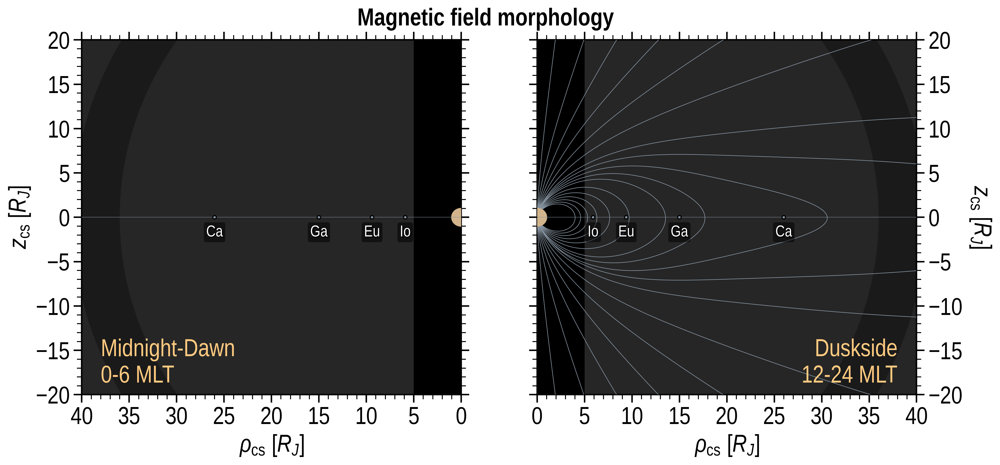

In [184]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor((0.15, 0.15, 0.15))
    ax.set_xlim(0.0, 40.0)
    ax.set_ylim(-20.0, 20.0)
    ax.set_xticks(np.arange(0, 40+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-20, 20+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    def draw_Galilean_moons(ax, facealpha=0.0):
        ax.axhline(y=0.0, color=UC.gray, linewidth=0.35, zorder=7)
        radii = [5.9, 9.4, 15.0, 26.0]
        name = ['Io', 'Eu', 'Ga', 'Ca']
        labelz = [-1.5, -1.5, -1.5, -1.5]
        for i in range(len(radii)):
            ax.add_patch(plt.Circle((radii[i], 0), 0.19, ec='k', fc=UC.gray,
                                    zorder=8, fill=True, clip_on=True))
            F.textbox(ax_idx=ax,
                      x=radii[i], y=labelz[i],
                      text=name[i],
                      textedge=True,
                      fontsize=F.fontsize*0.65,
                      facealpha=facealpha,
                      edgecolor='none',
                      horizontalalignment='center',
                      zorder=8)
        return None
    draw_Galilean_moons(ax, facealpha=0.5)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    def hatch_outer_36rj(ax):
        for r_in, r_out in [(36, 41)]:
            # 上半分（z_cs > 0, つまり角度0-180度）
            wedge_top = Wedge(
                center=(0, 0),      # 木星の位置
                r=r_out,            # 外半径
                theta1=0,           # 開始角度
                theta2=360,         # 終了角度
                width=r_out - r_in,  # 幅 = 4 RJ
                facecolor='k',
                edgecolor=None,
                alpha=0.30,
                linewidth=3.0,
                transform=ax.transData,
                zorder=4.9,
            )
            ax.add_patch(wedge_top)
            ax.axvspan(0, 5, fc='k', ec='none', zorder=4.9, alpha=1.0)
        return None
    hatch_outer_36rj(ax)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)


# ===========================================================
# Magnetic field line
# ===========================================================
def draw_field_line_0300(ax):
    for i in range(result_arr_N3.shape[0]):
        rho_cs = np.sqrt(result_arr_N3[i, 0, :]**2+result_arr_N3[i, 1, :]**2)
        ax.plot(rho_cs, result_arr_N3[i, 2, :],
                linewidth=0.55, color=UC.gray, zorder=5)
    for i in range(result_arr_S3.shape[0]):
        rho_cs = np.sqrt(result_arr_S3[i, 0, :]**2+result_arr_S3[i, 1, :]**2)
        ax.plot(rho_cs, result_arr_S3[i, 2, :],
                linewidth=0.55, color=UC.gray, zorder=5)
    return None


def draw_field_line_0600(ax):
    for i in range(result_arr_N2.shape[0]):
        rho_cs = np.sqrt(result_arr_N2[i, 0, :]**2+result_arr_N2[i, 1, :]**2)
        ax.plot(rho_cs, result_arr_N2[i, 2, :],
                linewidth=0.55, color=UC.gray, zorder=5)
    for i in range(result_arr_S2.shape[0]):
        rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
        ax.plot(rho_cs, result_arr_S2[i, 2, :],
                linewidth=0.55, color=UC.gray, zorder=5)
    return None


# draw_field_line_0300(ax)

# for i in range(result_arr_S2.shape[0]):
#     rho_cs = np.sqrt(result_arr_S2[i, 0, :]**2+result_arr_S2[i, 1, :]**2)
#     ax.plot(rho_cs, -result_arr_S2[i, 2, :],
#             linewidth=0.55, color=UC.yellow, zorder=5)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================


def dawn_midnight_latitude_label_left(ax):
    r_arc = 41.1  # RJ

    lat_deg_list = [-64.5, -54, -43, -31, -17.5, -10, -2.3, 10, 17]
    label_list = [6, 8, 10, 12, 14, 15, 16, 15, 14]
    for i in range(len(lat_deg_list)):
        lat_deg = lat_deg_list[i]
        lat_rad = np.deg2rad(lat_deg)
        rho_i = r_arc * np.cos(lat_rad)
        z_i = r_arc * np.sin(lat_rad)

        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

        ax.text(
            rho_i, z_i, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='center',
            rotation=0,
            zorder=10,
        )
    lat_x_list = [1, 3.2, 5, 7, 11, 18]
    label_list = [2, 4, 6, 8, 10, 12]
    for i in range(len(lat_x_list)):
        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
        ax.text(
            lat_x_list[i], 14, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='center',
            rotation=0,
            zorder=10,
        )
    lat_x_list = [4, 11]
    label_list = [2, 4]
    for i in range(len(lat_x_list)):
        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
        ax.text(
            lat_x_list[i], -39.8, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='bottom',
            rotation=0,
            zorder=10,
        )
    lat_x_list = [9, 13, 18]
    label_list = [20, 18, 17]
    for i in range(len(lat_x_list)):
        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
        ax.text(
            lat_x_list[i], 2, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='center',
            rotation=0,
            zorder=10,
        )
    return None


# dawn_midnight_latitude_label_left(ax)


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')


# ===========================================================
# Magnetic field line
# ===========================================================
def draw_field_line_1800(ax):
    for i in range(result_arr_N.shape[0]):
        rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
        ax.plot(rho_cs, result_arr_N[i, 2, :],
                linewidth=0.55, color=UC.gray, zorder=5)
    for i in range(result_arr_S.shape[0]):
        rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
        ax.plot(rho_cs, result_arr_S[i, 2, :],
                linewidth=0.55, color=UC.gray, zorder=5)
    return None


draw_field_line_1800(ax)


# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
def dusk_latitude_label_right(ax):
    r_arc = 41.1  # RJ

    lat_deg_list = [-63.5, -53, -41.5, -29, -16, -8.5, 8, 15.5]
    label_list = [6, 8, 10, 12, 14, 15, 15, 14]
    for i in range(len(lat_deg_list)):
        lat_deg = lat_deg_list[i]
        lat_rad = np.deg2rad(lat_deg)
        rho_i = r_arc * np.cos(lat_rad)
        z_i = r_arc * np.sin(lat_rad)

        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'

        """ax.text(
            rho_i, z_i, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='center',
            rotation=0,
            zorder=10,
        )"""
    for j in [-1, 1]:
        lat_x_list = [1.5, 3.2, 5.5, 8.0, 12, 19]
        label_list = [2, 4, 6, 8, 10, 12]
        for i in range(len(lat_x_list)):
            # ラベル文字列（例: "+10°", "-8°", "0°"）
            label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
            ax.text(
                lat_x_list[i], j*14, label,
                fontsize=F.fontsize*0.45,
                color='white',
                ha='center', va='center',
                rotation=0,
                zorder=10,
            )
    lat_x_list = [4.5, 12]
    label_list = [2, 4]
    for i in range(len(lat_x_list)):
        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
        ax.text(
            lat_x_list[i], -39.8, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='bottom',
            rotation=0,
            zorder=10,
        )
    lat_x_list = [9, 13, 17, 30.5]
    label_list = [20, 18, 17, 16]
    for i in range(len(lat_x_list)):
        # ラベル文字列（例: "+10°", "-8°", "0°"）
        label = f'{label_list[i]}°' if lat_deg != 0 else '0°'
        ax.text(
            lat_x_list[i], 2, label,
            fontsize=F.fontsize*0.45,
            color='white',
            ha='center', va='center',
            rotation=0,
            zorder=10,
        )
    return None


# dusk_latitude_label_right(ax)

fig.suptitle('Magnetic field morphology', y=0.95,
             fontsize=F.fontsize, fontweight="bold")

# Field line trace from the grid

In [48]:
# rho: 0.5〜40、0付近を細かく
t = np.linspace(0, 1, 120)
rho_cs_grid = 0.2 + (40.0 - 0.2) * t**2  # 乗数を上げるほど0付近が密

# z: -20〜20、0付近を細かく
z_cs_grid = 20.0 * np.sign(t * 2 - 1) * (t * 2 - 1)**2  # 対称に

RHO_CS, Z_CS = np.meshgrid(rho_cs_grid, z_cs_grid)

In [ ]:
grid_tracing = False

In [50]:
jm.Internal.Config(Model='jrm33', Degree=1, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')
csfield = CSField()
csfield.config(
    i_phi0=4.838275473116932E-5,  # 4.845093370096503E-5
    I_rho0=10.033388761574646,    # 10.45591036962724
    a0=2.8333677E-6,              # 1.87067601E-6
    MLT0=1.56400572,              # 2.7409048
    a1=14.95621835,               # 25.56805279
    MLT1=19.83627108,             # 18.83227378
    b1=4.2518,
    MLTb=-0.2086,
)

In [51]:
if grid_tracing:
    jm.Internal.Config(Model='jrm33', Degree=1, CartesianIn=True,
                       CartesianOut=True)
    jm.Con2020.Config(equation_type='integral')
    csfield = CSField()
    csfield.config(
        i_phi0=4.838275473116932E-5,  # 4.845093370096503E-5
        I_rho0=10.033388761574646,    # 10.45591036962724
        a0=2.8333677E-6,              # 1.87067601E-6
        MLT0=1.56400572,              # 2.7409048
        a1=14.95621835,               # 25.56805279
        MLT1=19.83627108,             # 18.83227378
        b1=4.2518,
        MLTb=-0.2086,
    )
    # ==============================================================
    # FIELD LINE TRACE IN THE CURRENT SHEET PLANE (1800 MLT DUSK)
    # FROM THR MAGNETOSPHERE
    # ==============================================================
    rho_cs0 = RHO_CS*RJ  # [m]
    phi_cs0 = 0.0             # [rad]
    z_cs0 = Z_CS*RJ      # [m]

    x_cs0 = rho_cs0*np.cos(phi_cs0)     # [m]
    y_cs0 = rho_cs0*np.sin(phi_cs0)     # [m]

    R = csfield.R_sys3_2_cs()
    RT = csfield.R_cs_2_sys3()

    Niter = 50000

    ds0 = 600000.0   # [m] 600000.0だと70分かかる
    p = 1.2

    i_foot_N = np.zeros(x_cs0.shape)
    i_distance_N = np.zeros(x_cs0.shape)

    # 北半球電離圏に向かう向き
    # -1: north; 1: south
    ns = -1
    for k in range(x_cs0.shape[1]):
        for j in range(x_cs0.shape[0]):
            s = 0
            pos_s3_0 = RT @ np.array([
                x_cs0[j, k], y_cs0[j, k], z_cs0[j, k]
            ])
            x = pos_s3_0[0].copy()
            y = pos_s3_0[1].copy()
            z = pos_s3_0[2].copy()
            if z_cs0[j, k] >= 0.0*RJ:
                ns = -1
            elif z_cs0[j, k] < 0.0*RJ:
                ns = -1
                pos_s3_0 = RT @ np.array([
                    x_cs0[j, k], y_cs0[j, k], -z_cs0[j, k]
                ])
                x = pos_s3_0[0].copy()
                y = pos_s3_0[1].copy()
                z = pos_s3_0[2].copy()
            for i in range(Niter):
                Bx0, By0, Bz0 = jm.Internal.Field(
                    x/RJ, y/RJ, z/RJ)       # [nT]
                Bx1, By1, Bz1 = csfield.magnetic_field_v2(
                    x/RJ, y/RJ, z/RJ,
                    MLT=18.0)  # [T]
                Bx = (Bx0*1E-9)+Bx1     # [T]
                By = (By0*1E-9)+By1     # [T]
                Bz = (Bz0*1E-9)+Bz1     # [T]

                # Sys III -> CS
                B_vec_cs = R @ np.array([float(Bx), float(By), float(Bz)])
                x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
                rho_cs = np.sqrt(x_cs**2 + y_cs**2)
                phi_cs = np.arctan2(y_cs, x_cs)
                B_rho_cs = B_vec_cs[0] * \
                    np.cos(phi_cs) + B_vec_cs[1]*np.sin(phi_cs)
                B_phi_cs = 0.0     # rho_cs - z_cs plane
                B_z_cs = B_vec_cs[2]
                B_vec_cs = np.array([
                    B_rho_cs * np.cos(phi_cs) - B_phi_cs * np.sin(phi_cs),
                    B_rho_cs * np.sin(phi_cs) + B_phi_cs * np.cos(phi_cs),
                    B_z_cs
                ])

                # CS -> Sys III
                B_vec_s3 = RT @ B_vec_cs
                B0 = math.sqrt(
                    B_vec_s3[0]**2+B_vec_s3[1]**2+B_vec_s3[2]**2)      # [T]

                ds = ds0/(np.log10(B0*1E+9))**p      # [m]
                s += ds

                # 座標更新 (x, y, z)
                x += (ds*B_vec_s3[0]/B0)*ns
                y += (ds*B_vec_s3[1]/B0)*ns
                z += (ds*B_vec_s3[2]/B0)*ns

                # 座標更新 (r, theta, phi)
                rs = math.sqrt(x**2 + y**2 + z**2)
                theta = math.acos(z/rs)
                phi = math.atan2(y, x)

                # 終了条件 (北の外側境界)
                if abs(z) > 30.0*RJ:
                    print('North edge [RJ]:')
                    i_foot_N[j, k] = np.nan
                    i_distance_N[j, k] = np.nan
                    break
                # 終了条件 (水平距離の外側境界)
                if math.sqrt(x**2+y**2) > 60.0*RJ:
                    print('Horizontal edge')
                    i_foot_N[j, k] = np.nan
                    i_distance_N[j, k] = np.nan
                    break
                # 終了条件 (水平距離の外側境界)
                if rs < (66854.0+500.0)*1E+3:
                    # CS座標での磁気余緯度 座標更新後に再計算
                    x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
                    rho_cs = math.sqrt(x_cs**2 + y_cs**2)
                    theta_i = math.degrees(math.atan2(rho_cs, abs(z_cs)))
                    i_foot_N[j, k] = theta_i
                    i_distance_N[j, k] = s
                    break
                # 終了していない
                if i == Niter-1:
                    print('Tracing was not completed.')

    np.savetxt(
        'results/FAC_grid/schematic/ionos_colatitude_1224_2.txt',
        i_foot_N
    )

    np.savetxt(
        'results/FAC_grid/schematic/ionos_distance_1224_2.txt',
        i_distance_N
    )

In [52]:
if grid_tracing:
    jm.Internal.Config(Model='jrm33', Degree=1, CartesianIn=True,
                       CartesianOut=True)
    jm.Con2020.Config(equation_type='integral')
    csfield = CSField()
    csfield.config(
        i_phi0=4.838275473116932E-5,  # 4.845093370096503E-5
        I_rho0=10.033388761574646,    # 10.45591036962724
        a0=2.8333677E-6,              # 1.87067601E-6
        MLT0=1.56400572,              # 2.7409048
        a1=14.95621835,               # 25.56805279
        MLT1=19.83627108,             # 18.83227378
        b1=4.2518,
        MLTb=-0.2086,
    )
    # ==============================================================
    # FIELD LINE TRACE IN THE CURRENT SHEET PLANE (0600 MLT DAWN)
    # FROM THR MAGNETOSPHERE
    # ==============================================================
    rho_cs0 = RHO_CS*RJ  # [m]
    phi_cs0 = 0.0             # [rad]
    z_cs0 = Z_CS*RJ      # [m]

    x_cs0 = rho_cs0*np.cos(phi_cs0)     # [m]
    y_cs0 = rho_cs0*np.sin(phi_cs0)     # [m]

    R = csfield.R_sys3_2_cs()
    RT = csfield.R_cs_2_sys3()

    Niter = 50000

    ds0 = 600000.0   # [m]
    p = 1.2

    i_foot_N2 = np.zeros(x_cs0.shape)
    i_distance_N2 = np.zeros(x_cs0.shape)

    # 北半球電離圏に向かう向き
    # -1: north; 1: south
    ns = -1
    for k in range(x_cs0.shape[1]):
        for j in range(x_cs0.shape[0]):
            s = 0
            pos_s3_0 = RT @ np.array([
                x_cs0[j, k], y_cs0[j, k], z_cs0[j, k]
            ])
            x = pos_s3_0[0].copy()
            y = pos_s3_0[1].copy()
            z = pos_s3_0[2].copy()
            if z_cs0[j, k] >= 0.0*RJ:
                ns = -1
            elif z_cs0[j, k] < 0.0*RJ:
                ns = -1
                pos_s3_0 = RT @ np.array([
                    x_cs0[j, k], y_cs0[j, k], -z_cs0[j, k]
                ])
                x = pos_s3_0[0].copy()
                y = pos_s3_0[1].copy()
                z = pos_s3_0[2].copy()
            for i in range(Niter):
                Bx0, By0, Bz0 = jm.Internal.Field(
                    x/RJ, y/RJ, z/RJ)       # [nT]
                Bx1, By1, Bz1 = csfield.magnetic_field_v2(
                    x/RJ, y/RJ, z/RJ,
                    MLT=6.0)  # [T]
                Bx = (Bx0*1E-9)+Bx1     # [T]
                By = (By0*1E-9)+By1     # [T]
                Bz = (Bz0*1E-9)+Bz1     # [T]

                # Sys III -> CS
                B_vec_cs = R @ np.array([float(Bx), float(By), float(Bz)])
                x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
                rho_cs = np.sqrt(x_cs**2 + y_cs**2)
                phi_cs = np.arctan2(y_cs, x_cs)
                B_rho_cs = B_vec_cs[0] * \
                    np.cos(phi_cs) + B_vec_cs[1]*np.sin(phi_cs)
                B_phi_cs = 0.0     # rho_cs - z_cs plane
                B_z_cs = B_vec_cs[2]
                B_vec_cs = np.array([
                    B_rho_cs * np.cos(phi_cs) - B_phi_cs * np.sin(phi_cs),
                    B_rho_cs * np.sin(phi_cs) + B_phi_cs * np.cos(phi_cs),
                    B_z_cs
                ])

                # CS -> Sys III
                B_vec_s3 = RT @ B_vec_cs
                B0 = math.sqrt(
                    B_vec_s3[0]**2+B_vec_s3[1]**2+B_vec_s3[2]**2)      # [T]

                ds = ds0/(np.log10(B0*1E+9))**p      # [m]
                s += ds

                # 座標更新 (x, y, z)
                x += (ds*B_vec_s3[0]/B0)*ns
                y += (ds*B_vec_s3[1]/B0)*ns
                z += (ds*B_vec_s3[2]/B0)*ns

                # 座標更新 (r, theta, phi)
                rs = math.sqrt(x**2 + y**2 + z**2)
                theta = math.acos(z/rs)
                phi = math.atan2(y, x)

                # 終了条件 (北の外側境界)
                if abs(z) > 30.0*RJ:
                    print('North edge [RJ]:')
                    i_foot_N2[j, k] = np.nan
                    i_distance_N2[j, k] = np.nan
                    break
                # 終了条件 (水平距離の外側境界)
                if math.sqrt(x**2+y**2) > 60.0*RJ:
                    print('Horizontal edge')
                    i_foot_N2[j, k] = np.nan
                    i_distance_N2[j, k] = np.nan
                    break
                # 終了条件 (水平距離の外側境界)
                if rs < (66854.0+500.0)*1E+3:
                    # CS座標での磁気余緯度 座標更新後に再計算
                    x_cs, y_cs, z_cs = csfield._sys3_2_cs(x/RJ, y/RJ, z/RJ)
                    rho_cs = math.sqrt(x_cs**2 + y_cs**2)
                    theta_i = math.degrees(math.atan2(rho_cs, abs(z_cs)))
                    i_foot_N2[j, k] = theta_i
                    i_distance_N2[j, k] = s
                    break
                # 終了していない
                if i == Niter-1:
                    print('Tracing was not completed.')

    np.savetxt(
        'results/FAC_grid/schematic/ionos_colatitude_0060_2.txt',
        i_foot_N2
    )

    np.savetxt(
        'results/FAC_grid/schematic/ionos_distance_0060_2.txt',
        i_distance_N2
    )

In [53]:
i_foot_N = np.loadtxt(
    'results/FAC_grid/schematic/ionos_colatitude_1224_2.txt'
)
i_distance_N = np.loadtxt(
    'results/FAC_grid/schematic/ionos_distance_1224_2.txt'
)

i_foot_N2 = np.loadtxt(
    'results/FAC_grid/schematic/ionos_colatitude_0060_2.txt'
)
i_distance_N2 = np.loadtxt(
    'results/FAC_grid/schematic/ionos_distance_0060_2.txt'
)

Text(0.5, 1.01, 'Ionospheric colatitude $\\theta_{\\rm i}$')

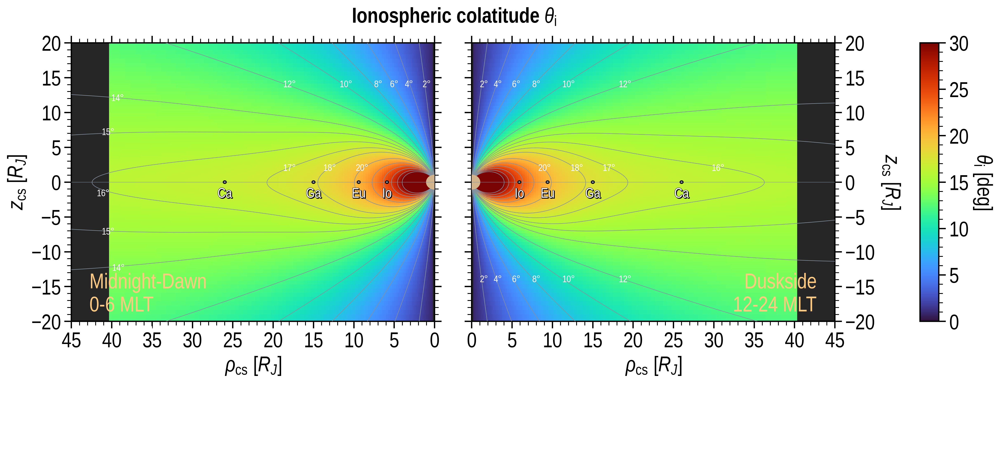

In [54]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor((0.15, 0.15, 0.15))
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-20.0, 20.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-20, 20+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    draw_Galilean_moons(ax)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    # hatch_outer_36rj(ax)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)

vmin = 0.0
vmax = 30.0
cmap = plt.get_cmap('turbo')
norm = mplC.Normalize(vmin=vmin, vmax=vmax)

cf = ax.pcolormesh(
    RHO_CS,
    Z_CS,
    i_foot_N2,
    norm=norm,
    cmap=cmap,
    # origin='lower',           # z軸が下から上に増加する向きに合わせる
    # extent=[
    #     RHO_CS.min(), RHO_CS.max(),
    #     Z_CS.min(),   Z_CS.max()
    # ],
    # aspect='auto',            # ax の縦横比に合わせて伸縮
    # interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)
# cs = ax.contour(RHO_CS_0060, Z_CS_0060, i_foot_N2, levels=20)
# ax.clabel(cs, inline=True, fontsize=15)

# ===========================================================
# Magnetic field line
# ===========================================================
draw_field_line_0600(ax)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
dawn_midnight_latitude_label_left(ax)


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')

vmin = 0.0
vmax = 30.0
cmap = plt.get_cmap('turbo')
norm = mplC.Normalize(vmin=vmin, vmax=vmax)

cf = ax.pcolormesh(
    RHO_CS,
    Z_CS,
    i_foot_N,
    norm=norm,
    cmap=cmap,
    # origin='lower',           # z軸が下から上に増加する向きに合わせる
    # extent=[
    #     RHO_CS.min(), RHO_CS.max(),
    #     Z_CS.min(),   Z_CS.max()
    # ],
    # aspect='auto',            # ax の縦横比に合わせて伸縮
    # interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)
# cs = ax.contour(RHO_CS_1224, Z_CS_1224, i_foot_N, levels=20)
# ax.clabel(cs, inline=True, fontsize=15)

# ===========================================================
# Magnetic field line
# ===========================================================
draw_field_line_1800(ax)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
dusk_latitude_label_right(ax)


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(cf, cax=cax)
pp.ax.set_yticks(np.arange(0, 30+1, 5))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
pp.ax.set_ylabel(
    r'$\theta_{\rm i}$ [deg]',
    verticalalignment='bottom',
    rotation=270)

fig.suptitle(r'Ionospheric colatitude $\theta_{\rm i}$', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

# plt.savefig('img/FAC_v2/ionospheric_colatitude_grid.pdf',
#             bbox_inches='tight')

In [55]:
def cut_gaussian(x, x1, x2, sigma_ratio=1/2):
    c, h = (x1 + x2) / 2, (x2 - x1) / 2
    sigma = h * sigma_ratio
    mask = (x >= x1) & (x <= x2)
    f = np.zeros_like(x, dtype=float)
    f[mask] = np.exp(-((x[mask] - c) ** 2) / (2 * sigma ** 2))
    # f[~mask] = np.nan
    return f

Text(0.5, 1.01, 'Ionospheric colatitude $\\theta_{\\rm i}$')

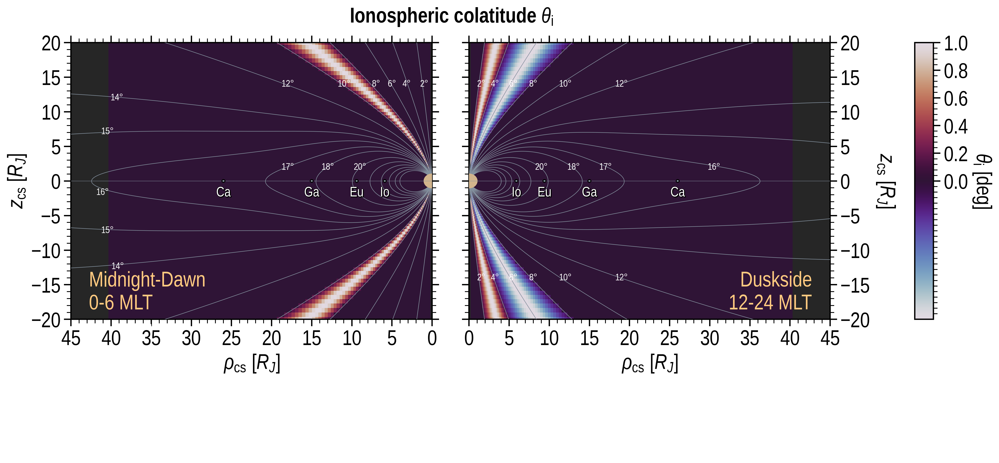

In [56]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor((0.15, 0.15, 0.15))
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-20.0, 20.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-20, 20+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    draw_Galilean_moons(ax)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    # hatch_outer_36rj(ax)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)

vmin = -1.0
vmax = 1.0
cmap = plt.get_cmap('twilight')
norm = mplC.Normalize(vmin=vmin, vmax=vmax)

cf = ax.pcolormesh(
    RHO_CS,
    Z_CS,
    cut_gaussian(i_foot_N2, 8, 10),
    norm=norm,
    cmap=cmap,
    # origin='lower',           # z軸が下から上に増加する向きに合わせる
    # extent=[
    #     RHO_CS.min(), RHO_CS.max(),
    #     Z_CS.min(),   Z_CS.max()
    # ],
    # aspect='auto',            # ax の縦横比に合わせて伸縮
    # interpolation='bicubic',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)
# cs = ax.contour(RHO_CS_0060, Z_CS_0060, i_foot_N2, levels=20)
# ax.clabel(cs, inline=True, fontsize=15)

# ===========================================================
# Magnetic field line
# ===========================================================
draw_field_line_0600(ax)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
dawn_midnight_latitude_label_left(ax)


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')

vmin = -1.0
vmax = 1.0
cmap = plt.get_cmap('twilight')
norm = mplC.Normalize(vmin=vmin, vmax=vmax)

cf = ax.pcolormesh(
    RHO_CS,
    Z_CS,
    cut_gaussian(i_foot_N, 2, 4)-cut_gaussian(i_foot_N, 4, 8),
    norm=norm,
    cmap=cmap,
    # origin='lower',           # z軸が下から上に増加する向きに合わせる
    # extent=[
    #     RHO_CS.min(), RHO_CS.max(),
    #     Z_CS.min(),   Z_CS.max()
    # ],
    # aspect='auto',            # ax の縦横比に合わせて伸縮
    # interpolation='bicubic',  # 滑らかに
    zorder=1,
)
# cs = ax.contour(RHO_CS_1224, Z_CS_1224, i_foot_N, levels=20)
# ax.clabel(cs, inline=True, fontsize=15)

# ===========================================================
# Magnetic field line
# ===========================================================
draw_field_line_1800(ax)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
dusk_latitude_label_right(ax)


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(cf, cax=cax)
pp.ax.set_yticks(np.linspace(0, 1, 6))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
pp.ax.set_ylabel(
    r'$\theta_{\rm i}$ [deg]',
    verticalalignment='bottom',
    rotation=270)

fig.suptitle(r'Ionospheric colatitude $\theta_{\rm i}$', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

# plt.savefig('img/FAC_v2/ionospheric_colatitude_grid.pdf',
#             bbox_inches='tight')

In [57]:
def smooth_and_interpolate_2d(x_1d, y_1d, data, sigma=1.0):
    """
    Parameters
    ----------
    x_1d : 1D array, shape (Nx,)
    y_1d : 1D array, shape (Ny,)
    data  : 2D array, shape (Ny, Nx)  ← meshgridと同じ軸順
    sigma : ガウシアンフィルターの標準偏差（グリッド点数単位）

    Returns
    -------
    interp_func : 呼び出し可能オブジェクト
        interp_func([[y, x], ...]) で任意点の値を返す
    """
    # 1. ガウシアンフィルター
    smoothed = gaussian_filter(data, sigma=sigma)

    # 2. 補間関数を構築（RegularGridInterpolatorはy, x順）
    interp_func = RegularGridInterpolator(
        (y_1d, x_1d),
        smoothed,
        method="linear",      # "nearest" / "linear" / "cubic" / "quintic"
        bounds_error=False,
        fill_value=None        # 範囲外はエッジ値で外挿。0にしたければ fill_value=0
    )
    return interp_func

In [114]:
# ===========================================================
# DATA
# ===========================================================
data_dawn = - cut_gaussian(i_foot_N, -3., 5.5)\
    + 0.7*cut_gaussian(i_foot_N, 6, 11) \
    - 0.4*cut_gaussian(i_foot_N, 12, 14) \
    + 0.4*cut_gaussian(i_foot_N, 14.5, 15) \
    - 0.6*cut_gaussian(i_foot_N, 15.5, 17.5)\
    + 0.3*cut_gaussian(i_foot_N, 18, 21)

data_dusk = - cut_gaussian(i_foot_N, -3., 5.5)\
    + cut_gaussian(i_foot_N, 6, 9) \
    - 0.5*cut_gaussian(i_foot_N, 9, 12) \
    + cut_gaussian(i_foot_N, 11, 15)\
    - cut_gaussian(i_foot_N, 15.5, 18.2)\
    + 0.5*cut_gaussian(i_foot_N, 18.5, 22.5)

# 補間関数を作成
interp_func_dawn = smooth_and_interpolate_2d(
    RHO_CS[0, :], Z_CS[:, 0], data_dawn, sigma=1.0
)
interp_func_dusk = smooth_and_interpolate_2d(
    RHO_CS[0, :], Z_CS[:, 0], data_dusk, sigma=1.0
)

# 新しい細かいグリッド全体に補間
x_new = np.linspace(np.min(RHO_CS), np.max(RHO_CS), 400)
y_new = np.linspace(np.min(Z_CS), np.max(Z_CS), 400)
x_new_grid, y_new_grid = np.meshgrid(x_new, y_new)
query_grid = np.stack([y_new_grid, x_new_grid], axis=-1)
data_dawn_new = 0.9*interp_func_dawn(query_grid)
data_dusk_new = 0.9*interp_func_dusk(query_grid)

Text(0.5, 1.01, 'Ionospheric colatitude $\\theta_{\\rm i}$')

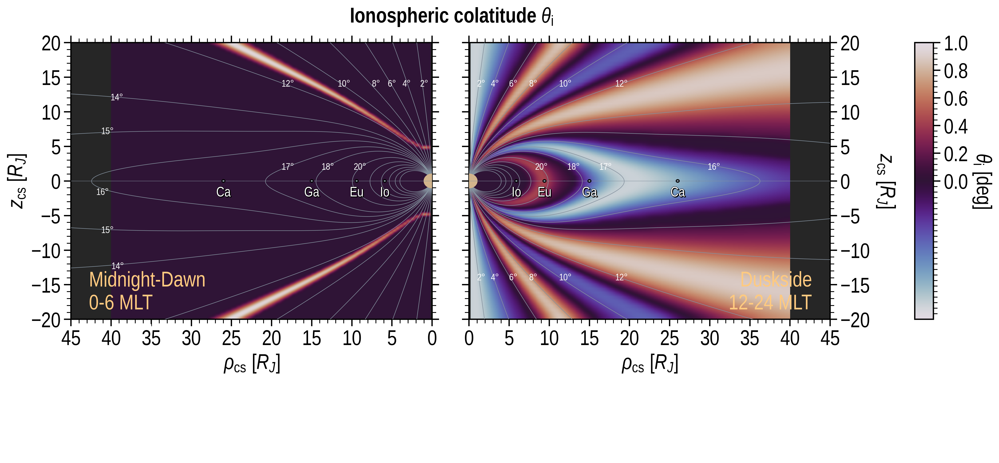

In [115]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(14, 8), dpi=326)

# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor((0.15, 0.15, 0.15))
    ax.set_xlim(0.0, 45.0)
    ax.set_ylim(-20.0, 20.0)
    ax.set_xticks(np.arange(0, 45+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-20, 20+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    draw_Galilean_moons(ax)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    # hatch_outer_36rj(ax)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Midnight-Dawn\n0-6 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)

vmin = -1.0
vmax = 1.0
cmap = plt.get_cmap('twilight')
norm = mplC.Normalize(vmin=vmin, vmax=vmax)

cf = ax.imshow(
    cut_gaussian(i_foot_N2, 8, 10),
    norm=norm,
    cmap=cmap,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS.min(), RHO_CS.max(),
        Z_CS.min(),   Z_CS.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='bicubic',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)
# cs = ax.contour(RHO_CS_0060, Z_CS_0060, i_foot_N2, levels=20)
# ax.clabel(cs, inline=True, fontsize=15)

# ===========================================================
# Magnetic field line
# ===========================================================
draw_field_line_0600(ax)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
dawn_midnight_latitude_label_left(ax)


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside\n12-24 MLT',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')

vmin = -1.0
vmax = 1.0
cmap = plt.get_cmap('twilight')
norm = mplC.Normalize(vmin=vmin, vmax=vmax)

cf = ax.imshow(
    data_dusk_new,
    norm=norm,
    cmap=cmap,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS.min(), RHO_CS.max(),
        Z_CS.min(),   Z_CS.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='nearest',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)
# cs = ax.contour(RHO_CS_1224, Z_CS_1224, i_foot_N, levels=20)
# ax.clabel(cs, inline=True, fontsize=15)

# ===========================================================
# Magnetic field line
# ===========================================================
draw_field_line_1800(ax)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
dusk_latitude_label_right(ax)


# ===========================================================
# Colorbar
# ===========================================================
fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.1, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(cf, cax=cax)
pp.ax.set_yticks(np.linspace(0, 1, 6))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
pp.ax.set_ylabel(
    r'$\theta_{\rm i}$ [deg]',
    verticalalignment='bottom',
    rotation=270)

fig.suptitle(r'Ionospheric colatitude $\theta_{\rm i}$', y=1.01,
             fontsize=F.fontsize, fontweight="bold")

# plt.savefig('img/FAC_v2/ionospheric_colatitude_grid.pdf',
#             bbox_inches='tight')

In [116]:
def make_twilight_black_center(N=512):
    cmap = plt.get_cmap('twilight')
    xs = np.linspace(0, 1, N)
    rgb_orig = np.array([cmap(x)[:3] for x in xs])
    rgb_new = rgb_orig.copy()
    half = N // 2
    center_orig = rgb_orig[half]

    for i in range(half + 1):
        t = i / half
        rgb_new[i] = np.clip(rgb_orig[i] - t * center_orig, 0, 1)

    for i in range(half, N):
        t = (i - half) / (N - 1 - half)
        rgb_new[i] = np.clip(rgb_orig[i] - (1 - t) * center_orig, 0, 1)

    return mplC.ListedColormap(rgb_new, name="twilight_black")


cmap_twilight_black = make_twilight_black_center()

In [117]:
def make_idl_blue_white_red_purple(N=512):
    """
    Blue/White (反転: 白→黒) + Red-Purple (正順: 黒→赤紫)
    を黒でつないだカラーマップ。
    全体の [0, 0.5) = Blue/White の reverse (白→黒)
           [0.5, 1] = Red-Purple の正順 (黒→赤紫)
    """
    half = N // 2
    colors = np.zeros((N, 3))

    xs = np.linspace(0, 1, half)

    # --- 左半分: IDL Blue/White を逆順（白→黒）---
    for i, x in enumerate(xs):
        x_rev = 1.0 - x  # 逆順
        t = x_rev
        # Red
        if t < 1/3:
            r = 4.0 * t - 2.992156863
        elif t < 2/3:
            r = 4.0 * t - 2.9882352941
        elif t < 2.9843137255/3:
            r = 4.0 * t - 2.9843137255
        else:
            r = t
        # Green
        g = 1.602642681354730 * t - 5.948580022657070e-1
        # Blue
        b = 1.356416928785610 * t + 3.345982835050930e-3
        colors[i] = [np.clip(r, 0, 1), np.clip(g, 0, 1), np.clip(b, 0, 1)]

    # --- 右半分: IDL Red-Purple 正順（黒→赤紫）---
    for i, x in enumerate(xs):
        t = x * 255.0
        # Red
        if t < 25.97288868211422:
            r = 3.07931034482759e0 * t - 1.62758620689655e0
        elif t < 154.7883608200706:
            r = (-0.002335409922053 * t + 1.770196213987500) * \
                t + 33.949335775363600
        else:
            r = 252.0
        r /= 255.0
        # Green
        g = ((7.125813968310300e-5 * t - 2.223039020276470e-2)
             * t + 2.367815929630070e0) * t - 7.739188304766140e1
        g /= 255.0
        # Blue
        thresh = (2.51577880184332e1 - 5.67741935483871e-1) / \
            (9.88497695852535e-1 - 1.70189098998888e-1)
        if t < thresh:
            b = 1.70189098998888e-1 * t - 5.67741935483871e-1
        elif t < 150.2124460352976:
            b = 9.88497695852535e-1 * t - 2.51577880184332e1
        else:
            b = (-3.85393764961783e-3 * t + 2.82261880442729e0) * \
                t - 2.13706208872841e2
        b /= 255.0
        colors[half + i] = [np.clip(r, 0, 1),
                            np.clip(g, 0, 1), np.clip(b, 0, 1)]

    cmap = mplC.ListedColormap(colors, name="IDL_BlueWhite_Black_RedPurple")
    return cmap


cmap_bw_rp = make_idl_blue_white_red_purple()

In [118]:
colors = ["#FF8082", "#000000", "#4DC4FF"]
cmap_plb = mplC.LinearSegmentedColormap.from_list(
    "pink_black_lightblue", colors, N=256
)

colors = ["#005AFF", "#FFFFFF", "#FF3300"]
cmap_bwr = mplC.LinearSegmentedColormap.from_list(
    "red_white_blue", colors, N=256
)


def darken(hex_color, factor=0.5):
    """factor: 0=黒, 1=元の色"""
    r, g, b = mplC.to_rgb(hex_color)
    h, s, v = colorsys.rgb_to_hsv(r, g, b)
    r2, g2, b2 = colorsys.hsv_to_rgb(h, s, v * factor)
    return (r2, g2, b2)


colors = [
    (0.00, darken("#005AFF", factor=0.8)),  # 暗い青
    (0.12, "#005AFF"),
    (0.50, "#FFFFFF"),
    (0.88, "#FF3300"),
    (1.00, darken("#FF3300", factor=0.8)),  # 暗い赤
]

cmap_bwr2 = mplC.LinearSegmentedColormap.from_list(
    "red_white_blue", colors, N=256
)

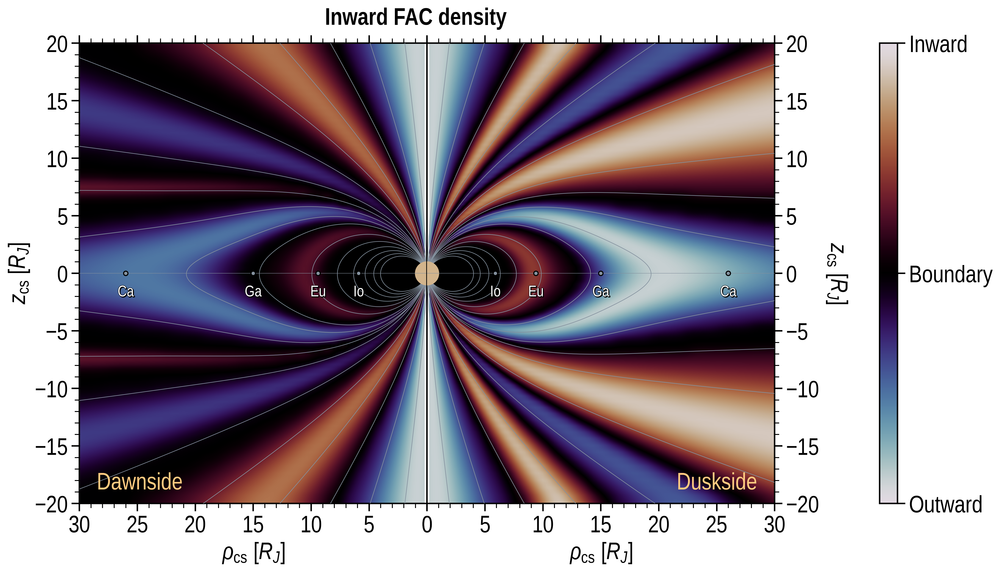

In [119]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(12, 8), dpi=326)
fig.subplots_adjust(wspace=0.0)
# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor((0.15, 0.15, 0.15))
    ax.set_facecolor('w')
    ax.set_xlim(0.0, 30.0)
    ax.set_ylim(-20.0, 20.0)
    ax.set_xticks(np.arange(0, 30+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-20, 20+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    draw_Galilean_moons(ax)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    # hatch_outer_36rj(ax)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    # right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Dawnside',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)

vmin = -1.0
vmax = 1.0
cmap = cmap_twilight_black
norm = mplC.Normalize(vmin=vmin, vmax=vmax)

cf = ax.imshow(
    data_dawn_new,
    norm=norm,
    cmap=cmap,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS.min(), RHO_CS.max(),
        Z_CS.min(),   Z_CS.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='bicubic',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)
# cs = ax.contour(RHO_CS_0060, Z_CS_0060, i_foot_N2, levels=20)
# ax.clabel(cs, inline=True, fontsize=15)

# ===========================================================
# Magnetic field line
# ===========================================================
draw_field_line_0600(ax)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
# dawn_midnight_latitude_label_left(ax)


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    left=False,
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside',
        color=UC.lightbeige,
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')

vmin = -1.0
vmax = 1.0
cmap = plt.get_cmap('RdBu_r')
cmap = cmap_bwr
# cmap = cmocean.cm.balance
cmap = cmap_twilight_black
norm = mplC.Normalize(vmin=vmin, vmax=vmax)

cf = ax.imshow(
    data_dusk_new,
    norm=norm,
    cmap=cmap,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS.min(), RHO_CS.max(),
        Z_CS.min(),   Z_CS.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='bicubic',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)
# cs = ax.contour(RHO_CS_1224, Z_CS_1224, i_foot_N, levels=20)
# ax.clabel(cs, inline=True, fontsize=15)

# ===========================================================
# Magnetic field line
# ===========================================================
draw_field_line_1800(ax)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
# dusk_latitude_label_right(ax)


# ===========================================================
# Colorbar
# ===========================================================
# fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.13, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(cf, cax=cax)
pp.ax.set_yticks(np.linspace(-1, 1, 3))
pp.ax.set_yticklabels(['Outward', 'Boundary', 'Inward'])
# pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))

fig.suptitle(r'Inward FAC density', y=0.94,
             fontsize=F.fontsize, fontweight="bold")

plt.savefig('img/FAC_v2/schematic_FAC_dawn_dusk.pdf',
            bbox_inches='tight')

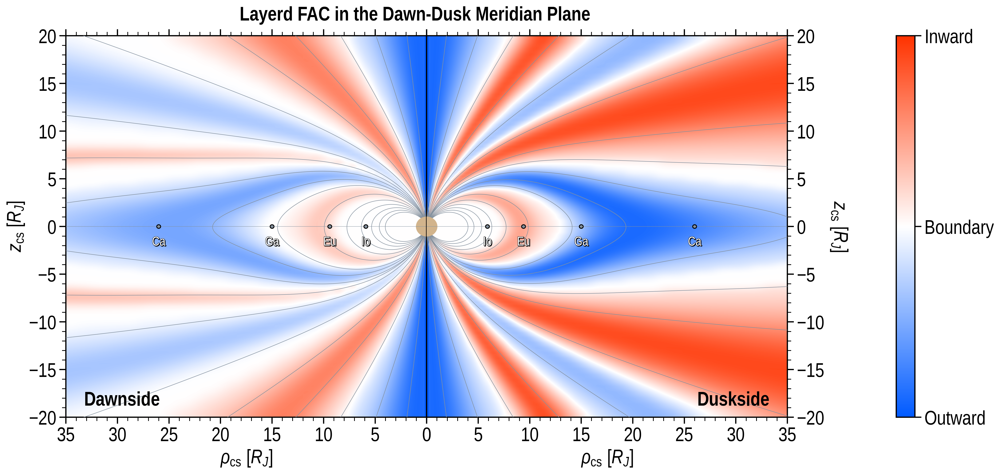

In [124]:
# ===========================================================
# プロット
# ===========================================================
F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

fig, axes = plt.subplots(1, 2, figsize=(15, 8), dpi=326)
fig.subplots_adjust(wspace=0.0)
# ===========================================================
# Common settings
# ===========================================================
for i in range(2):
    ax = axes[i]
    ax.set_facecolor((0.15, 0.15, 0.15))
    ax.set_facecolor(UC.blue)
    ax.set_xlim(0.0, 35.0)
    ax.set_ylim(-20.0, 20.0)
    ax.set_xticks(np.arange(0, 35+1, 5, dtype=int))
    ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_yticks(np.arange(-20, 20+1, 5, dtype=int))
    ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))
    ax.set_xlabel(r'$\rho_{\rm cs}$ [$R_J$]')
    ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]')

    # ===========================================================
    # Jupiter
    # ===========================================================
    ax.add_patch(plt.Circle((0, 0), 1.0, color='tan',
                            zorder=6, fill=True, clip_on=True))

    # ===========================================================
    # Galilean moons
    # ===========================================================
    draw_Galilean_moons(ax)

    # ===========================================================
    # Hatch mask outside 36 RJ
    # ===========================================================
    # hatch_outer_36rj(ax)


# ===========================================================
# Left panel (Dawn)
# ===========================================================
ax = axes[0]
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    # right=True,        # Show right tick marks
)
ax.xaxis.set_inverted(True)
ax.text(0.05, 0.02,
        'Dawnside',
        fontweight='bold',
        color='k',
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='left',
        transform=ax.transAxes,
        zorder=10)

vmin = -1.0
vmax = 1.0
cmap = cmap_bwr
norm = mplC.Normalize(vmin=vmin, vmax=vmax)

cf = ax.imshow(
    data_dawn_new,
    norm=norm,
    cmap=cmap,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS.min(), RHO_CS.max(),
        Z_CS.min(),   Z_CS.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='bicubic',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)
# cs = ax.contour(RHO_CS_0060, Z_CS_0060, i_foot_N2, levels=20)
# ax.clabel(cs, inline=True, fontsize=15)

# ===========================================================
# Magnetic field line
# ===========================================================
draw_field_line_0600(ax)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
# dawn_midnight_latitude_label_left(ax)


# ===========================================================
# Right panel (Dusk)
# ===========================================================
ax = axes[1]
ax.set_ylabel(r'$z_{\rm cs}$ [$R_J$]',
              verticalalignment='bottom',
              rotation=270, labelpad=28,)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
    left=False,
    labelleft=False,
    labelright=True,
)
ax.text(0.95, 0.02,
        'Duskside',
        fontweight='bold',
        color='k',
        fontsize=F.fontsize,
        verticalalignment='bottom',
        horizontalalignment='right',
        transform=ax.transAxes,
        zorder=10)
ax.yaxis.set_label_position('right')

vmin = -1.0
vmax = 1.0
cmap = plt.get_cmap('RdBu_r')
cmap = cmap_bwr
# cmap = cmocean.cm.balance
# cmap = cmap_twilight_black
norm = mplC.Normalize(vmin=vmin, vmax=vmax)

cf = ax.imshow(
    data_dusk_new,
    norm=norm,
    cmap=cmap,
    origin='lower',           # z軸が下から上に増加する向きに合わせる
    extent=[
        RHO_CS.min(), RHO_CS.max(),
        Z_CS.min(),   Z_CS.max()
    ],
    aspect='auto',            # ax の縦横比に合わせて伸縮
    interpolation='bicubic',  # pcolormesh と同じ「補間なし」の見た目
    zorder=1,
)
# cs = ax.contour(RHO_CS_1224, Z_CS_1224, i_foot_N, levels=20)
# ax.clabel(cs, inline=True, fontsize=15)

# ===========================================================
# Magnetic field line
# ===========================================================
draw_field_line_1800(ax)

# ===========================================================
# Latitude labels on arc of r=40 RJ
# ===========================================================
# dusk_latitude_label_right(ax)


# ===========================================================
# Colorbar
# ===========================================================
# fig.tight_layout()

axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.13, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(cf, cax=cax)
pp.ax.set_yticks(np.linspace(-1, 1, 3))
pp.ax.set_yticklabels(['Outward', 'Boundary', 'Inward'])
# pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(5))

fig.suptitle(r'Layerd FAC in the Dawn-Dusk Meridian Plane', y=0.94,
             fontsize=F.fontsize, fontweight="bold")

plt.savefig('img/FAC_v2/schematic_FAC_dawn_dusk_2.pdf',
            bbox_inches='tight')